# Olist Brazilian E-Commerce: Customer Behavior Analysis

> Run `scripts/load_data.py` and `scripts/run_analysis.py` first, then this notebook.

**Data**: Olist Brazilian E-Commerce public dataset, 99,441 orders, 2016-2018.

**Structure**: every section follows *business question -> method -> findings -> recommendations*.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data" / "processed" / "ecommerce.duckdb"), read_only=True)

def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()

sns.set_theme(style="whitegrid")

## 0. Data overview

In [2]:
q('''
SELECT COUNT(*) AS orders,
       COUNT(DISTINCT customer_unique_id) AS customers,
       MIN(purchased_at)::DATE AS first_order,
       MAX(purchased_at)::DATE AS last_order,
       ROUND(SUM(items_value), 0) AS total_gmv
FROM fct_orders
''')

,orders,customers,first_order,last_order,total_gmv
0,99441,96096,2016-09-04,2018-10-17,13591644.0


## 1. Sales trend
**Question**: how is the platform growing? Is growth driven by more customers or by bigger baskets?

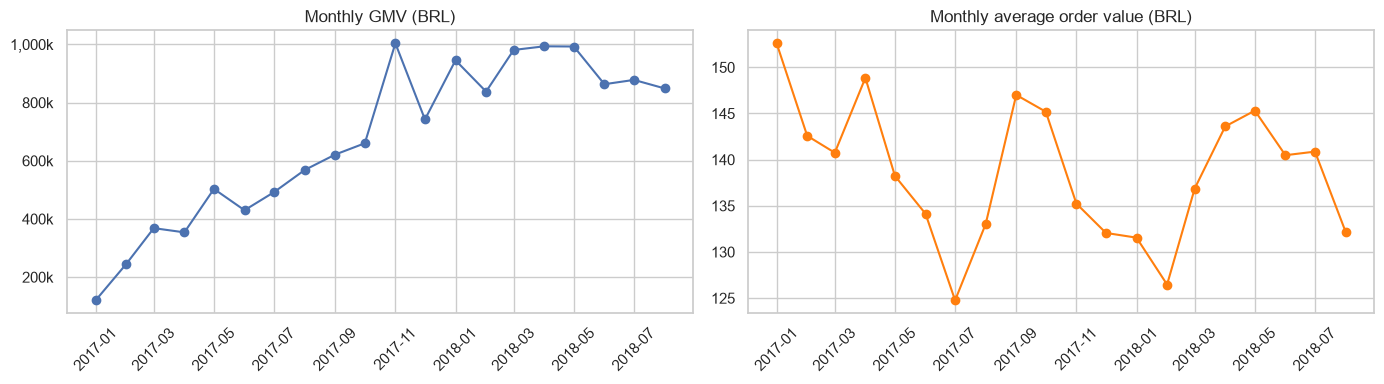

,month,orders,customers,gmv,aov,items_per_order
15,2018-04-01,6919,6863,993592.98,143.60,1.150
16,2018-05-01,6833,6775,992871.75,145.31,1.156
17,2018-06-01,6145,6106,863265.53,140.48,1.149
18,2018-07-01,6233,6172,878044.27,140.87,1.129
19,2018-08-01,6421,6380,848860.10,132.20,1.124


In [3]:
monthly = q("SELECT * FROM ana_monthly_sales")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(monthly.month, monthly.gmv, marker="o")
axes[0].set_title("Monthly GMV (BRL)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
axes[1].plot(monthly.month, monthly.aov, marker="o", color="tab:orange")
axes[1].set_title("Monthly average order value (BRL)")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIG / "01_monthly_sales.png", dpi=150); plt.show()
monthly.tail()

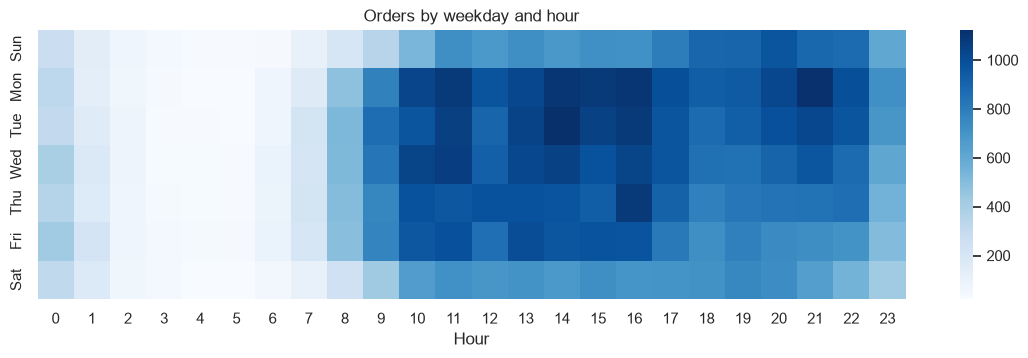

In [4]:
heat = q("SELECT * FROM ana_order_heatmap").pivot(index="weekday", columns="hour", values="orders")
heat.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"][: len(heat)]
plt.figure(figsize=(14, 3.5))
sns.heatmap(heat, cmap="Blues").grid(False)
plt.title("Orders by weekday and hour"); plt.xlabel("Hour"); plt.ylabel("")
plt.savefig(FIG / "02_order_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings**
- Monthly orders grew from ~1,700 on average in 2017 Q1 to ~6,800 in 2018 H1 (about 4x), while average order value stayed between 125 and 153 BRL: **growth came almost entirely from more customers, not bigger baskets**.
- November 2017 (Black Friday) peaked at 7,423 orders, 63% above October.
- From 2018 onwards GMV flattened at 0.85-1.0M BRL per month: **growth has plateaued**.
- Monday is the busiest day (16,196 orders) and Saturday the quietest (10,887, 33% lower); 10:00-16:00 is the daily peak.

**Recommendations**: with acquisition-led growth slowing, the next lever is repeat purchases and basket size (bundles, free-shipping thresholds). Time campaigns and support staffing for weekday daytime, and plan inventory for Black Friday-style events.

## 2. Fulfillment funnel
**Question**: where do orders drop off between purchase and delivery?

In [5]:
display(q("SELECT * FROM ana_order_funnel"))
display(q("SELECT * FROM ana_order_status"))

,step,stage,orders,pct_of_placed,pct_of_prev_step
0,1,1 Placed,99441,1.0000,NaN
1,2,2 Approved,99281,0.9984,0.9984
2,3,3 Shipped,97658,0.9821,0.9837
3,4,4 Delivered,96476,0.9702,0.9879


,order_status,orders,share
0,delivered,96478,0.9702
1,shipped,1107,0.0111
2,canceled,625,0.0063
3,unavailable,609,0.0061
4,invoiced,314,0.0032
5,processing,301,0.0030
6,created,5,0.0001
7,approved,2,0.0000


**Findings**
- 97.0% of orders are delivered; cancellations and "unavailable" orders together account for ~1.2%.
- The largest drop is **approved -> shipped** (98.4%, ~1,600 orders never shipped), so the problem sits with seller stock and dispatch rather than payments.

**Recommendations**: sync seller inventory and track seller dispatch SLAs to cut "unavailable" orders. Caveat: Olist has no clickstream data; with browsing logs the next step would be a view -> cart -> purchase conversion funnel.

## 3. Retention and repeat purchases
**Question**: do customers come back after their first purchase?

,orders_per_customer,customers,share
0,1,92102,0.9696
1,2,2652,0.0279
2,3,188,0.0020
3,4+,48,0.0005


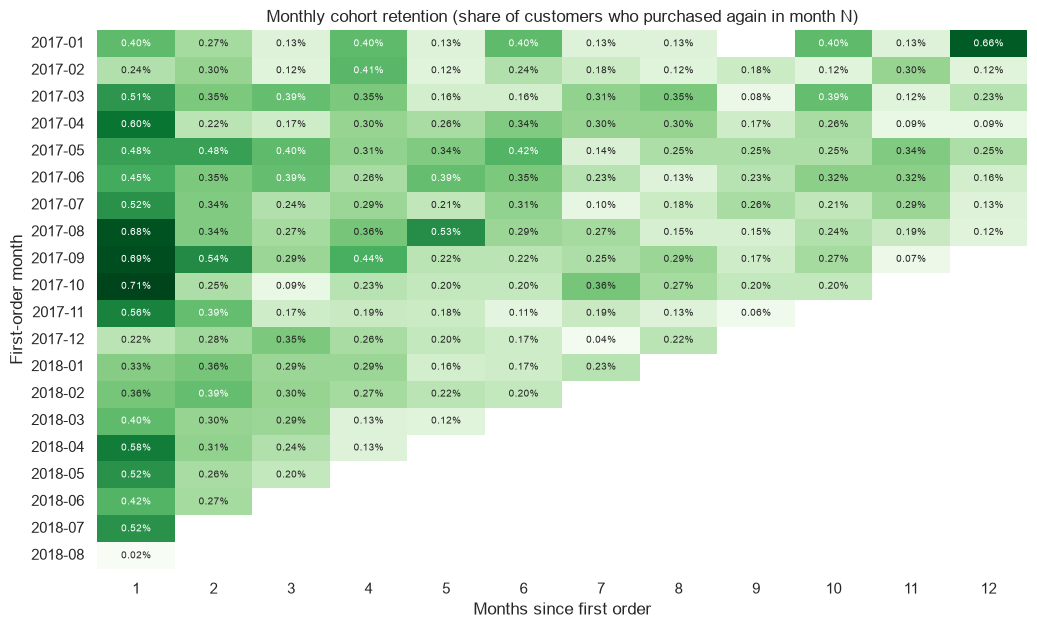

In [6]:
display(q("SELECT * FROM ana_repeat_purchase"))
cohort = q("SELECT * FROM ana_cohort_retention WHERE month_number BETWEEN 1 AND 12")
pivot = cohort.pivot(index="cohort_label", columns="month_number", values="retention_rate")
plt.figure(figsize=(12, 7))
sns.heatmap(pivot, annot=True, fmt=".2%", cmap="Greens", cbar=False, annot_kws={"size": 7}).grid(False)
plt.title("Monthly cohort retention (share of customers who purchased again in month N)")
plt.xlabel("Months since first order"); plt.ylabel("First-order month")
plt.savefig(FIG / "03_cohort_retention.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings**
- **97.0% of customers ordered only once**; just 2.8% ordered twice.
- Average month-1 retention across cohorts is ~0.5%, then stays around 0.2-0.3%.
- The platform depends almost entirely on new customers, so customer lifetime value is very low.

**Recommendations**: repeat purchases are the biggest growth opportunity. Send a second-order voucher 7-30 days after first delivery, add replenishment reminders for high-frequency categories (beauty, home) and introduce a loyalty program. Every 1 percentage point of repeat rate is roughly 950 extra returning customers.

## 4. RFM segmentation
**Question**: which customers are most valuable, and which need to be won back?

,segment,customers,customer_share,revenue,revenue_share,avg_recency_days,avg_monetary
0,1 Champions,956,0.0101,312590.55,0.0232,138.7,326.98
1,2 Loyal,1932,0.0203,437905.87,0.0325,337.0,226.66
2,3 Big Spenders,14696,0.1547,3944872.11,0.2923,141.8,268.43
3,4 Promising,22061,0.2322,1228918.41,0.0911,139.6,55.71
4,5 At Risk,14061,0.1480,3899201.66,0.2889,446.4,277.31
5,6 Need Attention,18378,0.1935,2395583.11,0.1775,270.2,130.35
6,7 Hibernating,22906,0.2411,1275329.03,0.0945,445.3,55.68


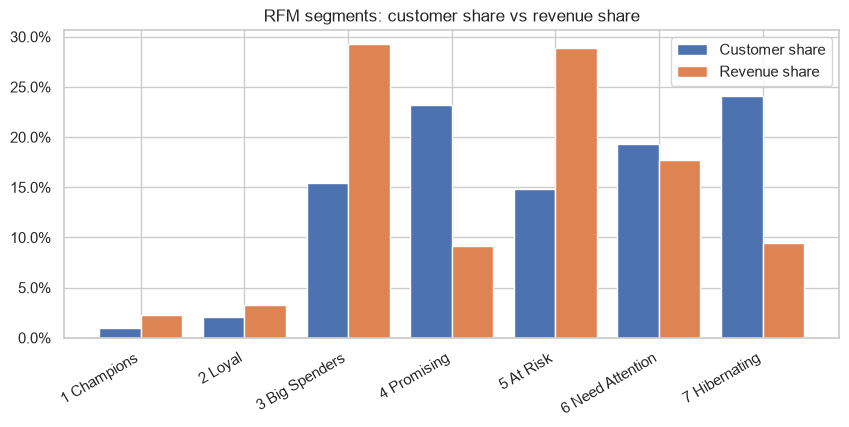

In [7]:
seg = q("SELECT * FROM ana_rfm_segments")
display(seg)
fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(seg))
ax.bar([i - 0.2 for i in x], seg.customer_share, width=0.4, label="Customer share")
ax.bar([i + 0.2 for i in x], seg.revenue_share, width=0.4, label="Revenue share")
ax.set_xticks(list(x)); ax.set_xticklabels(seg.segment, rotation=30, ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(); ax.set_title("RFM segments: customer share vs revenue share")
plt.savefig(FIG / "04_rfm_segments.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings**
- "Big Spenders" and "At Risk" together are **30% of customers but 58% of revenue**.
- "At Risk" alone has 14,058 customers and 28.9% of revenue, yet their last purchase was on average **446 days** ago.
- Because repeat purchases are so rare, "Champions" and "Loyal" together are only ~3% of customers.

**Recommendations**
- At Risk -> highest-priority win-back (personalised vouchers, new-arrival recommendations): best return on marketing spend
- Big Spenders -> push the second order quickly before they drift into At Risk
- Promising / Hibernating -> low-cost automated email and push campaigns

## 5. Deep dive: does delivery affect review scores?
**Question**: do late deliveries significantly lower review scores, and by how much?

**Method**: compare the review distributions of on-time and late orders. Review scores are ordinal (1-5) and not normally distributed, so a **Mann-Whitney U test** (non-parametric) is used instead of a t-test, with the rank-biserial correlation as the effect size.

In [8]:
display(q("SELECT * FROM ana_late_vs_review"))
display(q("SELECT * FROM ana_delivery_days_vs_review"))

scores = q('''
SELECT is_late, review_score FROM fct_orders
WHERE order_status = 'delivered' AND is_late IS NOT NULL AND review_score IS NOT NULL
''')
late = scores.loc[scores.is_late, "review_score"]
on_time = scores.loc[~scores.is_late, "review_score"]
u, p = stats.mannwhitneyu(on_time, late, alternative="greater")
# Effect size: rank-biserial correlation, from -1 to 1; larger absolute value = bigger difference
r = 2 * u / (len(on_time) * len(late)) - 1
print(f"On time n={len(on_time):,} mean={on_time.mean():.2f} | Late n={len(late):,} mean={late.mean():.2f}")
print(f"Mann-Whitney U={u:,.0f}, {'p < 1e-300' if p == 0 else f'p={p:.2e}'}, rank-biserial r={r:.3f}")

,delivery,orders,avg_review,bad_review_rate
0,Late,7661,2.567,0.5399
1,On time,88163,4.294,0.0919


,delivery_bucket,orders,avg_review,bad_review_rate
0,1) 0-7 days,30550,4.412,0.0755
1,2) 8-14 days,37775,4.299,0.0904
2,3) 15-21 days,16054,4.117,0.1212
3,4) 22-30 days,7265,3.545,0.2582
4,5) 30+ days,4180,2.204,0.6443


On time n=88,163 mean=4.29 | Late n=7,661 mean=2.57
Mann-Whitney U=524,735,918, p < 1e-300, rank-biserial r=0.554


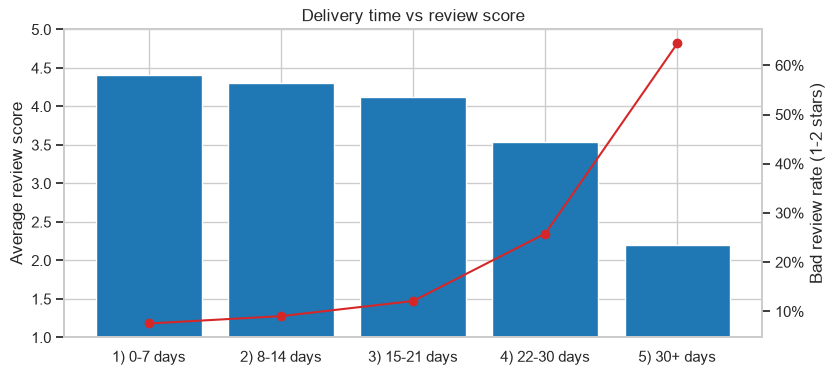

In [9]:
buckets = q("SELECT * FROM ana_delivery_days_vs_review")
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(buckets.delivery_bucket, buckets.avg_review, color="tab:blue")
ax1.set_ylabel("Average review score"); ax1.set_ylim(1, 5)
ax2 = ax1.twinx()
ax2.grid(False)
ax2.plot(buckets.delivery_bucket, buckets.bad_review_rate, color="tab:red", marker="o")
ax2.set_ylabel("Bad review rate (1-2 stars)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.title("Delivery time vs review score")
plt.savefig(FIG / "05_delivery_vs_review.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings**
- About **8% of delivered orders arrive late** (after the promised date).
- Late orders average **2.57** stars vs **4.29** for on-time orders; their bad review rate (1-2 stars) is **54%**, **5.9x** the on-time rate (9.2%).
- Mann-Whitney U test: p < 0.001, rank-biserial r = 0.55 (a large effect), so the gap is not due to chance.
- Orders taking more than 30 days get a 64% bad review rate; ~22 days is a clear tipping point.
- Large regional gaps: Sao Paulo (SP) averages 8.7 delivery days with a 5.9% late rate; Alagoas (AL) in the northeast averages 24.5 days with a 23.9% late rate.

**Recommendations**: logistics is the top driver of customer satisfaction. (1) Give more conservative delivery estimates for remote states ("under-promise, over-deliver"); (2) improve carrier partnerships in the northeast; (3) proactively notify and compensate customers when an order is predicted to be late.

## 6. Category performance

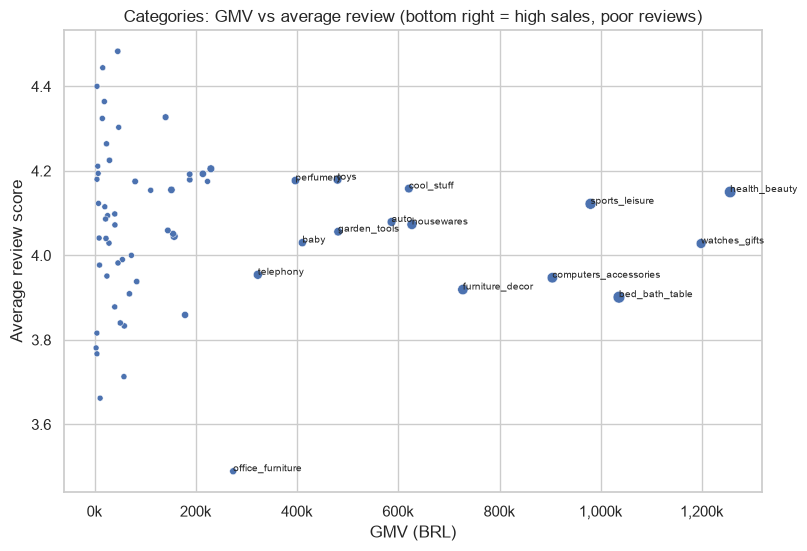

,category,orders,gmv,gmv_share,avg_price,freight_ratio,avg_review
0,health_beauty,8800,1255695.13,0.0931,130.34,0.3011,4.150
1,watches_gifts,5604,1198185.21,0.0888,200.70,0.1703,4.028
2,bed_bath_table,9399,1035964.06,0.0768,93.36,0.2842,3.901
3,sports_leisure,7673,979740.92,0.0726,114.06,0.2941,4.122
4,computers_accessories,6654,904322.02,0.0670,116.22,0.2951,3.947
5,furniture_decor,6425,727465.05,0.0539,87.67,0.3465,3.919
6,housewares,5847,626825.80,0.0465,90.65,0.4018,4.073
7,cool_stuff,3616,620770.49,0.0460,164.27,0.2205,4.158
8,auto,3872,586585.73,0.0435,139.53,0.3324,4.079
9,garden_tools,3505,481009.94,0.0356,111.14,0.3327,4.056


In [10]:
cat = q("SELECT * FROM ana_category_performance WHERE orders >= 30")
top = cat.head(15)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=cat, x="gmv", y="avg_review", size="orders", legend=False)
for _, row in top.iterrows():
    plt.annotate(row.category, (row.gmv, row.avg_review), fontsize=7)
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
plt.xlabel("GMV (BRL)"); plt.ylabel("Average review score")
plt.title("Categories: GMV vs average review (bottom right = high sales, poor reviews)")
plt.savefig(FIG / "06_category.png", dpi=150, bbox_inches="tight"); plt.show()
top

**Findings**
- Health & beauty (9.3% of GMV), watches & gifts (8.9%) and bed/bath/table (7.7%) are the top three categories.
- Among categories with 500+ orders, **office furniture has the lowest score (3.49)**; bed/bath/table and furniture/decor (~3.9) sell well but review poorly.
- Freight is ~35% of item price for furniture, well above average: shipping bulky items is likely hurting reviews.

**Recommendations**: prioritise logistics for bulky categories (specialist large-item carriers) and show more accurate delivery estimates on their product pages.

## 7. Summary

1. **Growth is acquisition-driven and repeat purchases are almost zero**: orders grew ~4x in two years, but 97% of customers bought only once and growth stalled in 2018. The next stage of growth has to come from retention.
2. **Delivery is the key driver of satisfaction**: late orders get 5.9x the bad review rate of on-time orders (effect size r = 0.55); northeastern states are late 2-4x as often as Sao Paulo.
3. **Revenue is concentrated**: 30% of customers generate 58% of revenue, and half of that group has not purchased in over a year. They are the first target for win-back campaigns.
4. **Bulky categories underperform**: furniture has high freight costs and low scores, making it the priority category for logistics improvements.